In [1]:
import sys, pathlib, warnings
warnings.filterwarnings("ignore")
_r = pathlib.Path.cwd().resolve()
while not (_r / "config" / "settings.yaml").exists() and _r != _r.parent:
    _r = _r.parent
sys.path.insert(0, str(_r))                      # makes `import src...` work from any folder
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import plotly.express as px
from src.notebook_utils import *
sns.set_theme(style="whitegrid"); pd.set_option("display.max_columns", 40, "display.width", 140)
print("project root:", _r)

project root: /app


# Consumer trust analysis
From Likert responses to the Consumer Trust Score (CTS), reliability and drivers. Survey data here is **synthetic** until real consented responses replace `survey/survey_data.csv`.

In [2]:
from src.trust_scoring.scoring import score_respondents, reliability_report, dimension_scores
from src.model_evaluation import statistics as st
sv = load_survey(); sc = score_respondents(sv, CFG); full = sv.merge(sc[['respondent_id','trust_score','segment']], on='respondent_id')
sc.describe().round(1)

,perceived_security,privacy_assurance,transparency,reliability,behavioural_intent,trust_score
count,355.0,355.0,355.0,355.0,355.0,355.0
mean,55.0,57.8,57.1,56.0,58.5,56.6
std,22.0,20.6,19.3,17.8,21.4,17.1
min,0.0,12.5,0.0,12.5,0.0,10.0
25%,37.5,50.0,50.0,50.0,50.0,46.2
50%,56.2,62.5,62.5,50.0,62.5,56.2
75%,68.8,75.0,75.0,62.5,75.0,67.5
max,100.0,100.0,100.0,100.0,100.0,95.6


In [3]:
pd.Series(reliability_report(sv)).round(3).to_frame('Cronbach alpha')

,Cronbach alpha
overall,0.906
perceived_security,0.838
privacy_assurance,0.601
transparency,0.517
reliability,0.490
behavioural_intent,0.647


<Axes: xlabel='segment'>

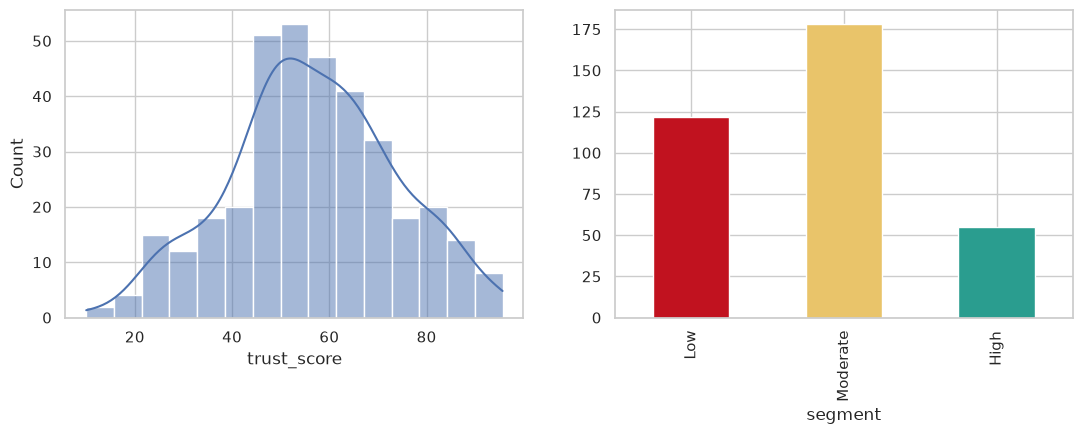

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(sc.trust_score, kde=True, ax=ax[0]); sc.segment.value_counts().reindex(['Low','Moderate','High']).plot.bar(ax=ax[1], color=['#c1121f','#e9c46a','#2a9d8f'])

In [5]:
st.correlation_with_p(full, 'trust_score', ['uses_mfa','experienced_fraud','digital_literacy'])

,variable,r,p_value
2,digital_literacy,0.478308,1.074362e-21
0,uses_mfa,0.430578,1.863861e-17
1,experienced_fraud,-0.224152,2.018638e-05


In [6]:
res = st.ols(full[['uses_mfa','experienced_fraud','digital_literacy']], full.trust_score); print('R2 =', round(res.attrs['r2'], 3)); res.round(4)

R2 = 0.36


,coef,std_err,t,p_value
intercept,56.5704,0.7306,77.4297,0.0
uses_mfa,4.6176,0.7941,5.8151,0.0
experienced_fraud,-4.0084,0.7306,-5.4864,0.0
digital_literacy,6.6504,0.7941,8.3750,0.0


{'H': 2.256492615445407, 'p_value': 0.688701046549596, 'groups': 5}


<Axes: xlabel='age_band', ylabel='trust_score'>

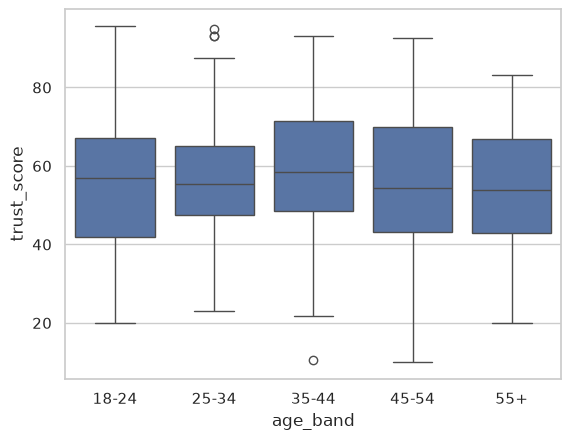

In [7]:
print(st.kruskal(full, 'trust_score', 'age_band')); sns.boxplot(data=full, x='age_band', y='trust_score', order=['18-24','25-34','35-44','45-54','55+'])

Interpretation guardrail: coefficients are *associations* on standardised predictors; the survey is cross-sectional, so no causal claim (e.g. that MFA *causes* trust) is made.